In [1]:
# Select the python interpreter in the virtual environment to be the jupyter kernel.
from collections import defaultdict
from pprint import pprint
import os, sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mne

import srt_gmlm_icassp_exps
from srt_gmlm_icassp_exps.config import PROJ_ROOT, EEG_ADHD_DATA_DIR
from srt_gmlm_icassp_exps.eeg_adhd import adhd_mne
from srt_gmlm_icassp_exps.eeg_adhd.adhd_mne import (
    create_subject_raw,
    parse_adhdata_to_mne,
    load_adhd_fif_dataset,
    EEG_CHANNELS
)
eeg_adhd_csv_path = EEG_ADHD_DATA_DIR / 'adhdata.csv'
fif_dset_path = EEG_ADHD_DATA_DIR / 'raw_fif'


2026-10-18 21:04:22.142 | INFO     | srt_gmlm_icassp_exps.config:<module>:11 - PROJ_ROOT path is: /mnt/ufs18/rs/ATD/SRT-GMLM


In [2]:
df = pd.read_csv(eeg_adhd_csv_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns)
df.head(10)

Dataset shape: (2166383, 21)
Columns: Index(['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7',
       'F8', 'T7', 'T8', 'P7', 'P8', 'Fz', 'Cz', 'Pz', 'Class', 'ID'],
      dtype='str')


,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,...,F8,T7,T8,P7,P8,Fz,Cz,Pz,Class,ID
0,261.0,402.0,16.0,261.0,126.0,384.0,126.0,236.0,52.0,236.0,...,16.0,200.0,494.0,126.0,236.0,121.0,367.0,121.0,ADHD,v10p
1,121.0,191.0,-94.0,85.0,16.0,200.0,126.0,52.0,347.0,273.0,...,-57.0,126.0,347.0,52.0,52.0,15.0,121.0,-19.0,ADHD,v10p
2,-55.0,85.0,-204.0,15.0,-57.0,200.0,52.0,126.0,236.0,200.0,...,-94.0,126.0,420.0,52.0,126.0,-55.0,261.0,85.0,ADHD,v10p
3,191.0,85.0,52.0,50.0,89.0,236.0,163.0,89.0,89.0,89.0,...,-57.0,236.0,420.0,126.0,126.0,15.0,85.0,-55.0,ADHD,v10p
4,-55.0,-125.0,-204.0,-160.0,-204.0,16.0,-241.0,-241.0,89.0,16.0,...,-131.0,89.0,310.0,-57.0,52.0,-55.0,15.0,-336.0,ADHD,v10p
5,-19.0,-90.0,-20.0,85.0,-20.0,200.0,-167.0,-20.0,-20.0,52.0,...,-57.0,200.0,494.0,126.0,163.0,50.0,156.0,-125.0,ADHD,v10p
6,-90.0,-195.0,-57.0,-55.0,-57.0,52.0,-131.0,-204.0,200.0,-20.0,...,-131.0,89.0,310.0,16.0,-57.0,15.0,-125.0,-336.0,ADHD,v10p
7,-336.0,-336.0,-278.0,-160.0,-167.0,-57.0,-278.0,-278.0,126.0,-167.0,...,-278.0,16.0,310.0,-20.0,-20.0,-19.0,-19.0,-231.0,ADHD,v10p
8,1388.0,1493.0,568.0,684.0,347.0,678.0,163.0,604.0,126.0,531.0,...,531.0,457.0,531.0,200.0,457.0,402.0,578.0,85.0,ADHD,v10p
9,1177.0,1282.0,273.0,473.0,89.0,494.0,-57.0,384.0,273.0,531.0,...,420.0,273.0,384.0,16.0,347.0,297.0,437.0,-19.0,ADHD,v10p


Number of subjects: 121
Time-point wise counts of classes:
------------------------------
           count  proportion
Class                       
ADHD     1207069    0.557182
Control   959314    0.442818


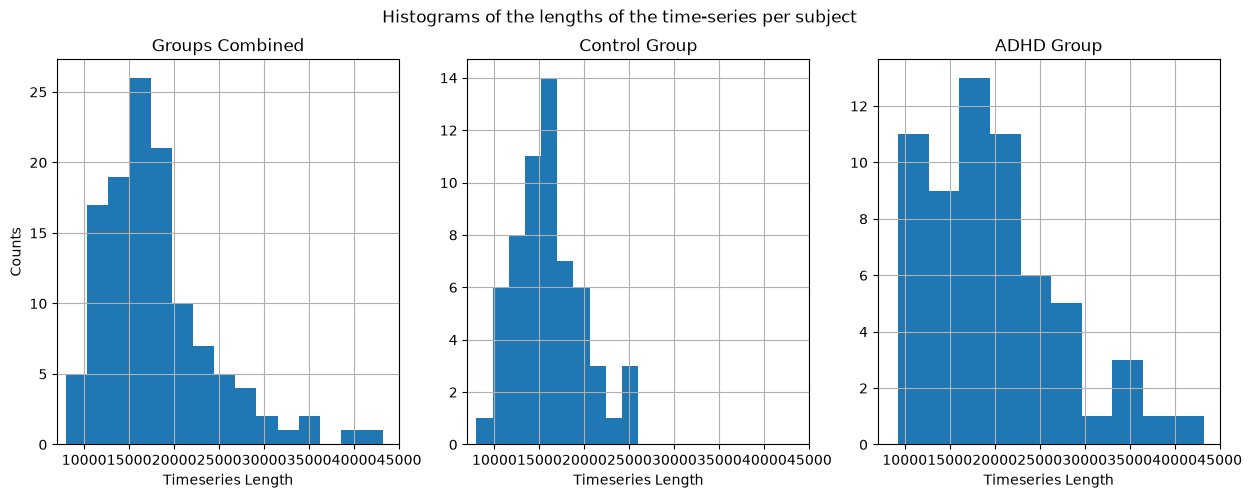

In [3]:
subj_ts_lens = df.value_counts('ID')
num_subj = len(subj_ts_lens)
print(f"Number of subjects: {num_subj}")

print("Time-point wise counts of classes:")
print("-"*30)
print(pd.concat((df.value_counts('Class'), df.value_counts('Class', normalize=True)), axis=1))
# df.drop_duplicates

adhd_idx = df['Class'] == 'ADHD'
adhd_df = df[adhd_idx]
control_idx = df['Class'] == 'Control'
control_df = df[control_idx]

ctrl_subj_ts_lens = control_df.value_counts('ID')
adhd_subj_ts_lens = adhd_df.value_counts('ID')
fig, axes = plt.subplots(1, 3, figsize=(15,5))

subj_ts_lens.hist(bins=15, ax=axes[0])
axes[0].set_title("Groups Combined")
ctrl_subj_ts_lens.hist(ax=axes[1])
axes[1].set_title("Control Group")
adhd_subj_ts_lens.hist(ax=axes[2])
axes[2].set_title("ADHD Group")
fig.suptitle("Histograms of the lengths of the time-series per subject")
axes[0].set_ylabel("Counts")
# axes[1].set_xlabel('Timeseries Length')

for ax in axes:
#     ax.set_ylabel("Counts")
    ax.set_xlabel('Timeseries Length')
    ax.set_xlim(xmin=7000,xmax=45000)

**Observation:** The ADHD group tends to have longer or shorter sessions, while control groups timeseries lengths seem more normally distributed.

**Comment:** Some subjects may be overrepresented while others may be underrepresented if we fit our models to the data without making necessary adjustments.

## Parsing by Subject

In [4]:
subject_ids = list(df.value_counts('ID').index)
dataset = {
    'ids': subject_ids,
    'adhd_ids': [],
    'control_ids': [],
    'ts_lengths': {},
    'num_samples': {},       # Number of samples per subject. Defaults to timeseries length for each subject.
    'covariate_dims': (19,), # Dimensions of the sample covariates.
    'response_dims': (1,),   # Dimensions of the sample responses.
    # We will create uniform samples from each subjects time-series. Since the
    # lengths of the timeseries vary, the number of samples also will vary
    # per subject. We will use 'num_samples' to derive weights to each sample.
    'subject_data': defaultdict(dict),
    'raws': {},              # MNE RawArray objects keyed by subject ID
}
# Subject Data will have the following structure
# {
#   'df': pd.DataFrame,
#   'Class': 'ADHD' or 'Control',
#   'ID': Subject Identifier,
#   'X': torch.Tensor of dimension: (n_samples, *covariate_dims)
#   'y': torch.Tensor of dimension: (n_samples, *response_dims)
#   'raw': mne.io.RawArray with 10-20 montage, sfreq=128Hz, scale=1e-6 (V)
# }

# Standard 10-20 montage for the 19 EEG channels
montage = mne.channels.make_standard_montage('standard_1020')

# Let's check if there is an error in the designated classes for each subject
inconsistent_subjects = []
for i, id in enumerate(subject_ids):
    subj_df = df[df['ID'] == id]

    dataset['subject_data'][id]['df'] = subj_df.drop(columns=['ID', 'Class'])
    subj_class = subj_df['Class'].iloc[-1]
    dataset['subject_data'][id]['ID'] = id
    dataset['subject_data'][id]['Class'] = subj_class
    dataset['subject_data'][id]['X'] = dataset['subject_data'][id]['df'].to_numpy()
    dataset['subject_data'][id]['y'] = (subj_df['Class'] == 'ADHD').to_numpy().reshape(-1,1)

    # Process into MNE RawArray (19 channels, 128 Hz, microvolts to Volts scale, 10-20 montage)
    raw = create_subject_raw(
        subj_df=dataset['subject_data'][id]['df'],
        subj_id=id,
        subj_class=subj_class,
        channels=EEG_CHANNELS,
        sfreq=128.0,
        scale=1e-6,
        montage_name='standard_1020',
        verbose=False,
    )
    dataset['subject_data'][id]['raw'] = raw
    dataset['raws'][id] = raw

    if subj_df.isnull().any(axis=None) or subj_df.isna().any(axis=None):
        print(f"Subject {id} has Null or NaN entries")
    if not (subj_df['Class'] == subj_class).all():
        inconsistent_subjects.append(id)

    if subj_class == 'ADHD':
        dataset['adhd_ids'].append(id)
    elif subj_class == 'Control':
        dataset['control_ids'].append(id)
    else:
        print(f'Class {subj_class} not recognized for {id}')
    dataset['ts_lengths'][id] = len(subj_df)
    dataset['num_samples'][id] = dataset['ts_lengths'][id]

if len(inconsistent_subjects) >0:
    print(f"Following subjects have inconsistent class labels.")
    print(inconsistent_subjects)
else:
    print(f"Successfully processed all {len(dataset['ids'])} subjects into MNE Raw objects ({len(dataset['adhd_ids'])} ADHD, {len(dataset['control_ids'])} Control).")
    print("None of the subject timeseries have label inconsistency.")

Successfully processed all 121 subjects into MNE Raw objects (61 ADHD, 60 Control).
None of the subject timeseries have label inconsistency.


In [5]:
subj_df = dataset['subject_data']['v15p']['df']
raw_v15p = dataset['subject_data']['v15p']['raw']

print(subj_df.columns)
print("ID:	", dataset['subject_data']['v15p']['ID'])
print("Class:	", dataset['subject_data']['v15p']['Class'])
print("X shape:", dataset['subject_data']['v15p']['X'].shape)
print("y shape:", dataset['subject_data']['v15p']['y'].shape)
print("--- MNE Raw Representation ---")
print(raw_v15p)
print(raw_v15p.info)
print("Duration (s):", raw_v15p.times[-1])
print("Sampling Frequency (Hz):", raw_v15p.info['sfreq'])
print("Channel types:", set(raw_v15p.get_channel_types()))

Index(['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7',
       'F8', 'T7', 'T8', 'P7', 'P8', 'Fz', 'Cz', 'Pz'],
      dtype='str')
ID:	 v15p
Class:	 ADHD
X shape: (43252, 19)
y shape: (43252, 1)
--- MNE Raw Representation ---
<RawArray | 19 x 43252 (337.9 s), ~6.3 MiB, data loaded>
<Info | 10 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T7, T8, P7, ...
 chs: 19 EEG
 custom_ref_applied: False
 description: Class: ADHD
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 64.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 128.0 Hz
 subject_info: <subject_info | his_id: v15p>
>
Duration (s): 337.8984375
Sampling Frequency (Hz): 128.0
Channel types: {'eeg'}


## Statistical Analysis

In [6]:
df.describe()

,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T7,T8,P7,P8,Fz,Cz,Pz
count,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06
mean,1.360903e+02,1.361619e+02,1.422117e+02,1.361022e+02,1.422737e+02,1.422005e+02,1.422755e+02,1.419608e+02,1.419823e+02,1.416007e+02,1.420600e+02,1.415633e+02,1.417452e+02,1.413199e+02,1.416635e+02,1.410618e+02,1.352097e+02,1.351830e+02,1.352074e+02
std,2.755497e+02,2.755136e+02,2.206503e+02,2.133873e+02,2.234852e+02,2.107195e+02,2.301860e+02,2.095699e+02,2.360460e+02,2.133996e+02,2.432087e+02,2.265186e+02,2.272337e+02,2.273205e+02,2.079590e+02,2.048027e+02,2.522447e+02,2.130295e+02,2.274500e+02
min,-3.786000e+03,-1.322400e+04,-3.921000e+03,-1.323700e+04,-3.921000e+03,-3.921000e+03,-3.921000e+03,-3.958000e+03,-3.995000e+03,-3.921000e+03,-3.995000e+03,-3.958000e+03,-3.958000e+03,-3.995000e+03,-3.921000e+03,-3.958000e+03,-3.786000e+03,-3.751000e+03,-3.751000e+03
25%,1.500000e+01,1.500000e+01,5.200000e+01,1.500000e+01,5.200000e+01,5.200000e+01,1.600000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,1.500000e+01,1.500000e+01,1.500000e+01
50%,1.210000e+02,1.210000e+02,1.260000e+02,1.210000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.210000e+02,1.210000e+02,1.210000e+02
75%,2.610000e+02,2.260000e+02,2.360000e+02,2.260000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.610000e+02,2.260000e+02,2.260000e+02
max,1.381300e+04,4.802000e+03,5.020000e+03,4.802000e+03,5.430000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.064000e+03,5.016000e+03,5.020000e+03,4.802000e+03,4.802000e+03,4.802000e+03


## Visualization of the 10-20 EEG Sensor Layout

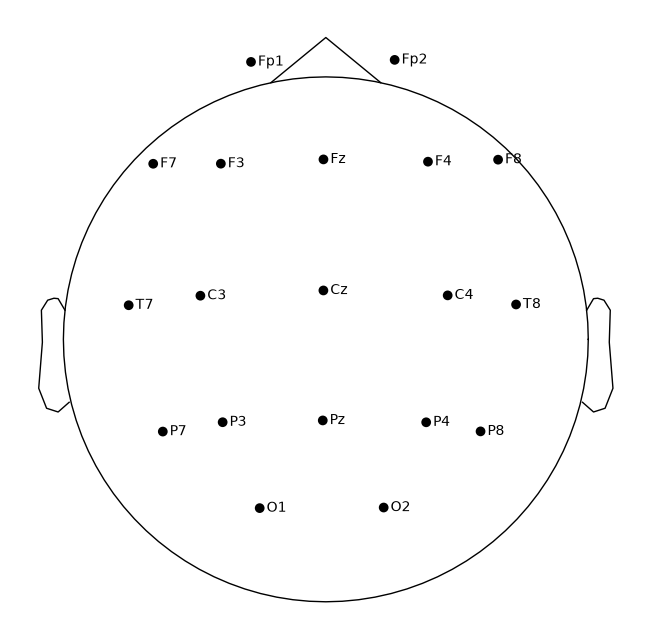

In [7]:
# Visualize 10-20 sensor montage layout
fig = raw_v15p.plot_sensors(show_names=True, title="ADHD 10-20 EEG Sensor Layout")
plt.show()

Power spectral density estimation on subject v15p

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


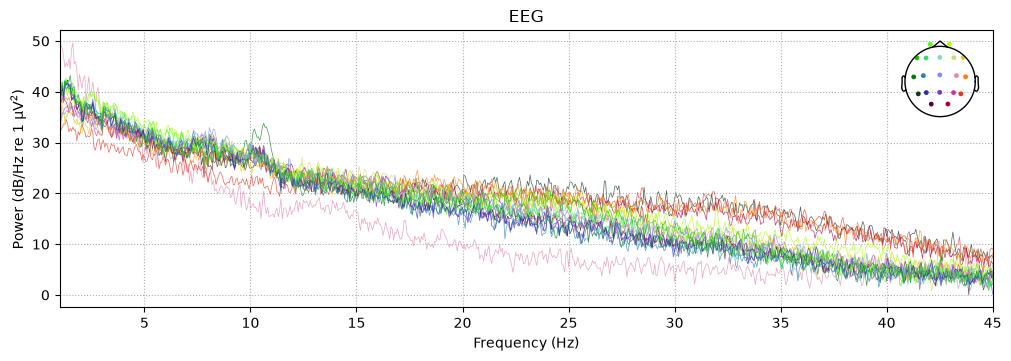

In [8]:
# Compute and plot Power Spectral Density (PSD) using MNE Welch method
psd = raw_v15p.compute_psd(fmin=1.0, fmax=45.0)
fig = psd.plot()
plt.show()